# 10 — Factor residual returns of the best zero-cost strategy

Does the notebook 6 strategy earn returns beyond common exposures? We use its **same saved highest-Sharpe portfolio**, without rerunning or changing trades.

1. Regress daily portfolio excess returns on S&P 500 excess returns and oil price changes.
2. Repeat with the U.S. Fama–French three factors: market excess return, **SMB (size)**, and **HML (value)**.
3. Add oil to the Fama–French model to control for market, size, value, and oil simultaneously; then repeat the regressions on individual stocks used by the strategy.

The risk-free return is subtracted from portfolio and market returns, rather than regressing on a Treasury yield level. Both models use French's daily one-month T-bill return so their results are comparable. We also check the existing lagged three-month Treasury proxy.

This is a retrospective attribution of a strategy selected on this sample. Alpha tests do not correct for that selection. Costs are zero, factor data are revised historical snapshots, and no final holdout is opened. Stock residuals are diagnostics; we do not trade residualized prices or reconstruct a new portfolio.

In [ ]:
from pathlib import Path
import sys, json, io, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import statsmodels.api as sm
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent  
sys.path.insert(0, str(ROOT / 'src'))
from risk_free import load_treasury_yields
RUN_ID = None  # Same selection rule as notebook 6; specify if multiple runs exist.
runs = sorted(p.parent for p in (ROOT / 'outputs/joint_grid_search_zero_cost').glob('*/grid_summary.csv'))
if RUN_ID is None:
    if len(runs) != 1:
        raise ValueError(f'Set RUN_ID to one of {[p.name for p in runs]}')
    run = runs[0]
else:
    run = ROOT / 'outputs/joint_grid_search_zero_cost' / RUN_ID
summary = pd.read_csv(run / 'grid_summary.csv')
complete = summary.loc[summary.Status.eq('complete') & np.isfinite(summary['Sharpe Ratio'])]
if complete.empty:
    raise ValueError('No completed strategy with finite Sharpe ratio')
winner = complete.sort_values('Sharpe Ratio', ascending=False, kind='stable').iloc[0]
folder = run / Path(winner['Output Folder']).name
params = json.loads((folder / 'parameters.json').read_text())
assert params['cost_bps_per_leg'] == 0
portfolio = pd.read_csv(folder / 'portfolio_daily.csv', parse_dates=['Date']).set_index('Date').sort_index()
assert portfolio.index.is_unique and portfolio.index.max() < pd.Timestamp('2023-08-25')
assert np.isfinite(portfolio['Net Return']).all()
np.testing.assert_allclose((1 + portfolio['Net Return']).cumprod(), portfolio.Equity / params['initial_capital'], atol=1e-10)
selected = pd.read_csv(folder / 'selected_pairs.csv')
tickers = sorted(set(selected.A) | set(selected.B))
OUT = ROOT / 'outputs/factor_residual_analysis_zero_cost' / run.name / folder.name
OUT.mkdir(parents=True, exist_ok=True)
print(f"Saved Sharpe: {winner['Sharpe Ratio']:.4f}; total return: {winner['Cumulative Return']:.2%}")
print(f'{portfolio.index.min():%Y-%m-%d} to {portfolio.index.max():%Y-%m-%d}; {len(portfolio):,} sessions; {len(tickers)} selected stocks')
print('Parameters:', params)


Saved Sharpe: 0.3594; total return: 18.61%
2016-07-01 to 2023-08-24; 1,799 sessions; 99 selected stocks
Parameters: {'formation_months': 18, 'trading_months': 6, 'correlation_threshold': 0.8, 'eg_significance': 0.01, 'entry_z': 1.5, 'exit_z': 0.5, 'stop_z': 4.0, 'run_id': 'cb64c19613e1e11beb71', 'cost_bps_per_leg': 0.0, 'initial_capital': 100000.0}


## Factor data and alignment

Cached raw downloads and SHA-256 hashes live in `data/factors/notebook10`. Reruns use these snapshots without network access.

- **S&P 500:** Yahoo Finance `^GSPC` closing price index, [historical prices](https://finance.yahoo.com/quote/%5EGSPC/history/). This is a price return, excluding dividends; it is a beta proxy rather than an investable total-return benchmark.
- **Oil:** EIA [Brent spot prices via FRED, DCOILBRENTEU](https://fred.stlouisfed.org/series/DCOILBRENTEU), dollars/barrel. We use simple percentage price changes, not price levels. Brent avoids the negative WTI price episode in 2020. Oil spot changes are an exposure proxy, not futures investment returns or a broad commodity factor.
- **Risk-free and Fama–French:** [French U.S. daily data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), with [factor definitions](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html). Percent observations are divided by 100. Mkt−RF already excludes RF; SMB and HML are long-short returns and must not have RF subtracted again.

Prices are aligned to the portfolio trading calendar **before** computing changes. No prices or returns are filled. If an oil observation or its preceding trading-session price is missing, that day's oil return is missing. All three main models use the same complete dates; omitted dates are reported and saved. Returns are never calculated by jumping across a missing equity-market session. Contemporaneous factors are for attribution, with imperfect cross-market closing-time alignment.

In [2]:
CACHE = ROOT / 'data/factors/notebook10'
sources = json.loads((CACHE / 'sources.json').read_text())
for name, meta in sources.items():
    assert hashlib.sha256((CACHE / name).read_bytes()).hexdigest() == meta['sha256'], name
j = json.loads((CACHE / 'sp500_yahoo.json').read_text())['chart']['result'][0]
assert j['meta']['symbol'] == '^GSPC'
sp = pd.Series(j['indicators']['quote'][0]['close'],
               index=pd.to_datetime(j['timestamp'], unit='s', utc=True).tz_convert('America/New_York').tz_localize(None).normalize(), name='SP500 price')
assert sp.index.is_unique
brent_frame = pd.read_csv(CACHE / 'brent_fred.csv', na_values=['.'])
brent = pd.Series(pd.to_numeric(brent_frame['DCOILBRENTEU']).to_numpy(),
                  index=pd.to_datetime(brent_frame.iloc[:, 0]), name='Brent price')
assert brent.index.is_unique and brent.dropna().gt(0).all()
with zipfile.ZipFile(CACHE / 'ff3_daily.zip') as archive:
    text = archive.read(archive.namelist()[0]).decode('utf-8-sig')
lines = text.splitlines()
header = next(line for line in lines if line.replace(' ', '').startswith(',Mkt-RF,SMB,HML,RF'))
rows = [line for line in lines if len(line.split(',')[0].strip()) == 8 and line.split(',')[0].strip().isdigit()]
ff = pd.read_csv(io.StringIO('\n'.join([header] + rows)), index_col=0)
ff.index = pd.to_datetime(ff.index.astype(str), format='%Y%m%d')
ff = ff.apply(pd.to_numeric)
assert ff.index.is_unique
ff = ff.mask(ff.le(-99)) / 100  # French missing-value sentinels, then percentage -> decimal.
# Include preceding sessions so the first backtest return has its correct prior price.
calendar = sp.index[sp.index <= portfolio.index.max()].sort_values()
prices = pd.concat([sp.reindex(calendar), brent.reindex(calendar)], axis=1)
price_returns = prices.pct_change(fill_method=None).rename(columns={'SP500 price': 'SP500', 'Brent price': 'Oil'})
data = portfolio[['Net Return']].join(price_returns).join(ff[['Mkt-RF', 'SMB', 'HML', 'RF']])
data['SP500-RF'] = data.SP500 - data.RF
data['Portfolio-RF'] = data['Net Return'] - data.RF
needed = ['Net Return', 'SP500-RF', 'Oil', 'Mkt-RF', 'SMB', 'HML', 'RF', 'Portfolio-RF']
coverage = data[needed].isna().sum().rename('Missing sessions').to_frame()
display(coverage)
omitted = data.loc[data[needed].isna().any(axis=1)]
omitted.to_csv(OUT / 'omitted_dates.csv')
sample = data[needed].dropna().copy()
assert len(sample) > 252 and np.isfinite(sample).all().all()
print(f'Common regression sample: {len(sample):,} / {len(portfolio):,} sessions; {len(omitted)} omitted.')
print(f'{sample.index.min():%Y-%m-%d} to {sample.index.max():%Y-%m-%d}')
display(sample.head())


,Missing sessions
Net Return,0
SP500-RF,0
Oil,46
Mkt-RF,0
SMB,0
HML,0
RF,0
Portfolio-RF,0


Common regression sample: 1,753 / 1,799 sessions; 46 omitted.
2016-07-01 to 2023-08-24


,Net Return,SP500-RF,Oil,Mkt-RF,SMB,HML,RF,Portfolio-RF
Date,,,,,,,,
2016-07-01,0.000000,0.001949,-0.008325,0.0024,0.0052,-0.0043,0.0,0.000000
2016-07-05,0.000371,-0.006847,-0.042183,-0.0084,-0.0063,-0.0137,0.0,0.000371
2016-07-06,0.000243,0.005353,0.001315,0.0062,0.0017,-0.0012,0.0,0.000243
2016-07-07,0.000014,-0.000872,0.005033,0.0002,0.0033,-0.0018,0.0,0.000014
2016-07-08,-0.000148,0.015253,-0.030481,0.0159,0.0092,0.0032,0.0,-0.000148


## Regression and residual definitions

For each model fit $r_{p,t}-r_{f,t}=\alpha+\beta^\top f_t+\epsilon_t$ by OLS with an intercept. Report coefficient estimates, Newey–West/HAC standard errors (5 observed-session lags), two-sided p-values, 95% confidence intervals, and $R^2$. Alpha annualization is **252 × daily alpha**, an arithmetic attribution convention.

- **Strict residual:** $\epsilon_t = (r_{p,t}-r_{f,t})-\hat\alpha-\hat\beta^\top f_t$. Its full-sample mean is zero by construction, so its Sharpe cannot establish an edge.
- **Factor-adjusted excess return retaining alpha:** $(r_{p,t}-r_{f,t})-\hat\beta^\top f_t=\hat\alpha+\epsilon_t$. This is the useful series for evaluating the remaining average return.

Compounded adjusted-return paths are illustrative hypothetical paths, not returns of an executed hedge. Contributions reconcile **additively per day**; compounded contributions do not sum to the actual compounded return. Full-sample estimates use future observations relative to earlier dates; the later rolling check addresses this fitting issue.

In [3]:
MODELS = {
    'SP500 + oil': ['SP500-RF', 'Oil'],
    'Fama-French 3': ['Mkt-RF', 'SMB', 'HML'],
    'Fama-French 3 + oil': ['Mkt-RF', 'SMB', 'HML', 'Oil'],
}
HAC_LAGS = 5

def fit_model(y, factors, lags=HAC_LAGS):
    X = sm.add_constant(factors, has_constant='add')
    if np.linalg.matrix_rank(X) != X.shape[1]:
        raise ValueError('Rank-deficient factor matrix')
    fit = sm.OLS(y, X, missing='raise').fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    ci = fit.conf_int()
    table = pd.DataFrame({'Coefficient': fit.params, 'HAC std error': fit.bse,
                          'HAC t': fit.tvalues, 'p-value': fit.pvalues,
                          '95% lower': ci[0], '95% upper': ci[1]})
    return fit, table

fits, coefficients, paths, metrics = {}, {}, {}, []

def analyze(name):
    cols = MODELS[name]
    y = sample['Portfolio-RF']
    fit, table = fit_model(y, sample[cols])
    contribution = sample[cols].mul(fit.params[cols], axis=1)
    adjusted = y - contribution.sum(axis=1)
    path = pd.DataFrame({'Raw return': sample['Net Return'], 'RF': sample.RF,
                         'Excess return': y, 'Factor explained': contribution.sum(axis=1),
                         'Alpha retained': adjusted, 'Strict residual': fit.resid})
    np.testing.assert_allclose(y, fit.params['const'] + contribution.sum(axis=1) + fit.resid, atol=1e-12)
    np.testing.assert_allclose(adjusted, fit.params['const'] + fit.resid, atol=1e-12)
    assert abs(fit.resid.mean()) < 1e-12
    np.testing.assert_allclose(sm.add_constant(sample[cols]).T @ fit.resid, 0, atol=1e-10)
    fits[name], coefficients[name], paths[name] = fit, table, path
    ci = fit.conf_int().loc['const'] * 252
    metrics.append({'Model': name, 'Sessions': len(y), 'R squared': fit.rsquared,
        'Alpha annual (arithmetic)': fit.params['const'] * 252,
        'Alpha 95% lower': ci[0], 'Alpha 95% upper': ci[1], 'Alpha HAC p-value': fit.pvalues['const'],
        'Residual annual volatility': fit.resid.std(ddof=1) * np.sqrt(252),
        'Adjusted mean / vol (annual)': adjusted.mean() / adjusted.std(ddof=1) * np.sqrt(252)})
    display(table.round(6))
    print(f"R²: {fit.rsquared:.3%}; arithmetic annual alpha: {fit.params['const'] * 252:.3%}; HAC p: {fit.pvalues['const']:.4f}")
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    for col in ['Raw return', 'Excess return', 'Alpha retained', 'Strict residual']:
        assert path[col].gt(-1).all()
        axes[0].plot(path.index, (1 + path[col]).cumprod() - 1, label=col)
    axes[0].set_title(name + ': compounded paths on common observed dates')
    axes[0].set_ylabel('Cumulative return')
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
    axes[0].legend()
    axes[1].plot(path.index, path['Alpha retained'].rolling(126, min_periods=126).mean() * 252,
                 label='126-observation mean × 252')
    axes[1].set_ylabel('Adjusted excess mean (annual)')
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].legend()
    for ax in axes:
        ax.axhline(0, color='gray', lw=.7)
        ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(OUT / (name.replace(' ', '_') + '_returns.png'), dpi=150)
    plt.show()
    path.to_csv(OUT / (name.replace(' ', '_') + '_daily.csv'))
    contribution.to_csv(OUT / (name.replace(' ', '_') + '_factor_contributions.csv'))


## 1. S&P 500, oil, and risk-free adjustment

Fit portfolio excess returns on S&P 500 excess returns and Brent changes. This controls for equity beta and an oil proxy; it does **not** control for size yet.

,Coefficient,HAC std error,HAC t,p-value,95% lower,95% upper
const,0.000043,0.000039,1.102476,0.270255,-0.000033,0.000119
SP500-RF,0.004937,0.004671,1.056951,0.290534,-0.004218,0.014092
Oil,-0.002275,0.001683,-1.351890,0.176411,-0.005573,0.001023


R²: 0.282%; arithmetic annual alpha: 1.076%; HAC p: 0.2703


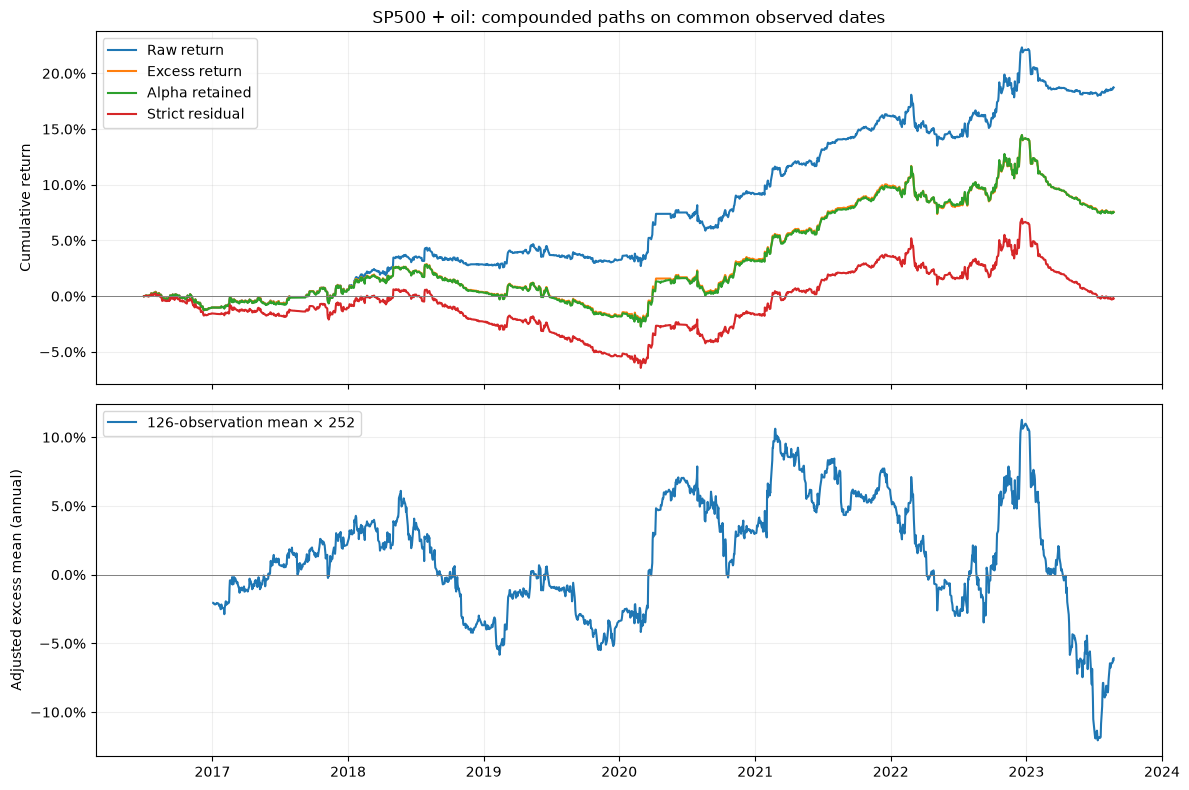

In [4]:
analyze('SP500 + oil')

## 2. Fama–French residualization

Use market, size, and value returns. Positive SMB exposure means sensitivity to small stocks outperforming large stocks; HML captures value versus growth. This model replaces the first factor set, so oil is not included until the combined sensitivity below.

,Coefficient,HAC std error,HAC t,p-value,95% lower,95% upper
const,0.000041,0.000039,1.055244,0.291314,-0.000035,0.000118
Mkt-RF,0.004089,0.004648,0.879737,0.379002,-0.005021,0.013199
SMB,-0.003664,0.010017,-0.365726,0.714570,-0.023297,0.015970
HML,0.006801,0.005013,1.356655,0.174891,-0.003024,0.016626


R²: 0.270%; arithmetic annual alpha: 1.040%; HAC p: 0.2913


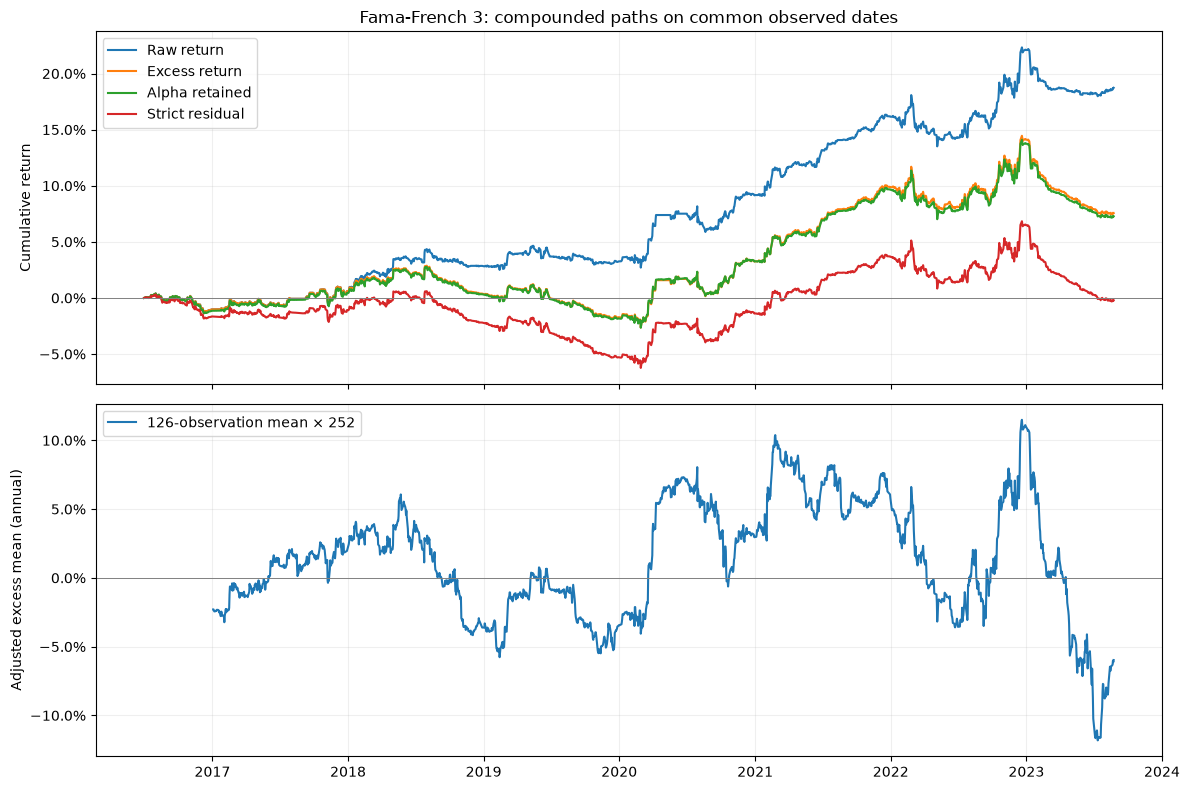

In [5]:
analyze('Fama-French 3')

## Combined factors and comparison

The combined model controls for oil alongside market, size, and value. All models use the same dates and RF. The adjusted mean/volatility ratio is an arithmetic excess-return statistic; notebook 6 uses a CAGR-based Sharpe, so the two need not agree.

,Coefficient,HAC std error,HAC t,p-value,95% lower,95% upper
const,0.000043,0.000039,1.096432,0.272890,-0.000034,0.000119
Mkt-RF,0.006130,0.004955,1.236983,0.216093,-0.003583,0.015842
SMB,-0.004235,0.010213,-0.414630,0.678413,-0.024251,0.015782
HML,0.008572,0.004999,1.714667,0.086406,-0.001226,0.018370
Oil,-0.002816,0.001717,-1.639940,0.101018,-0.006182,0.000550


R²: 0.589%; arithmetic annual alpha: 1.076%; HAC p: 0.2729


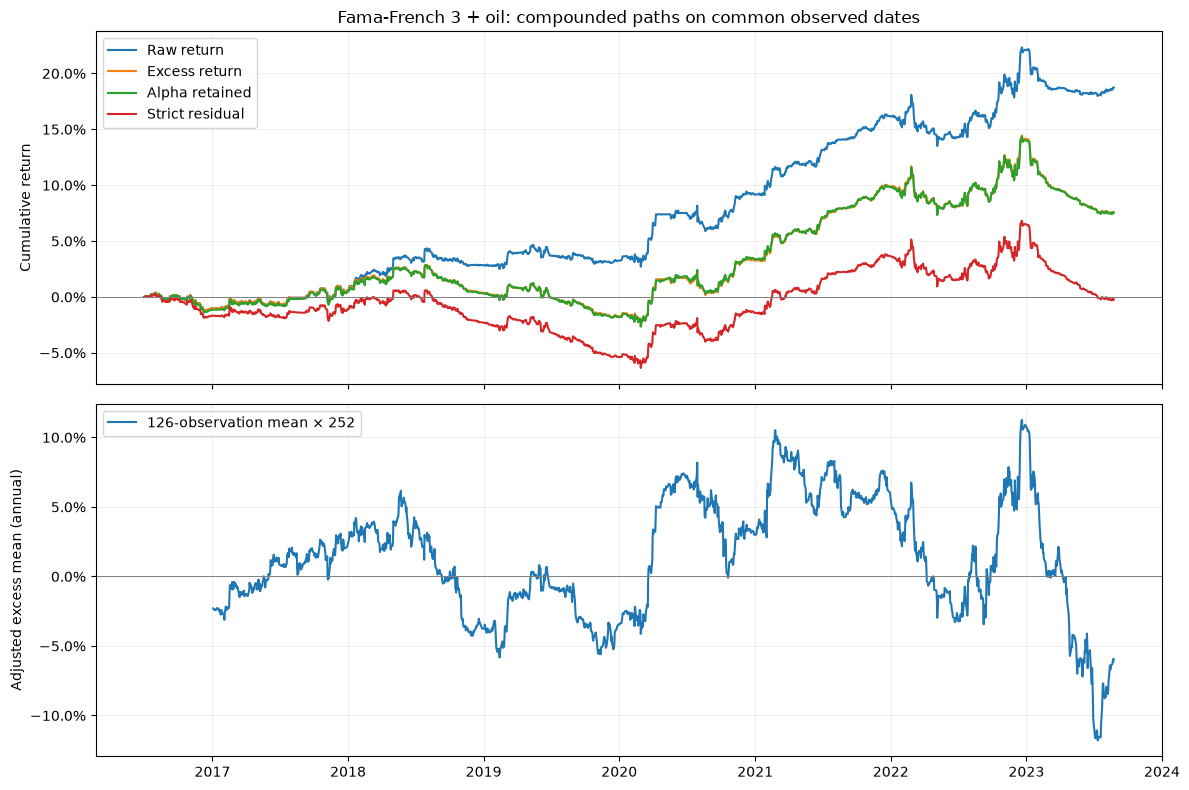

,Sessions,R squared,Alpha annual (arithmetic),Alpha 95% lower,Alpha 95% upper,Alpha HAC p-value,Residual annual volatility,Adjusted mean / vol (annual)
Model,,,,,,,,
SP500 + oil,1753.0000,0.0028,0.0108,-0.0084,0.0299,0.2703,0.0250,0.4304
Fama-French 3,1753.0000,0.0027,0.0104,-0.0089,0.0297,0.2913,0.0250,0.4163
Fama-French 3 + oil,1753.0000,0.0059,0.0108,-0.0085,0.0300,0.2729,0.0250,0.4312


Raw common-sample excess mean/vol ratio: 0.4312


,HAC 5 alpha p,HAC 21 alpha p
Model,,
SP500 + oil,0.270255,0.295122
Fama-French 3,0.291314,0.319522
Fama-French 3 + oil,0.272890,0.298817


S&P + oil with existing DGS3MO proxy: annual alpha 0.989%, HAC p 0.3115
Annualized mean RF: French 1.420%; lagged DGS3MO 1.509%


In [6]:
analyze('Fama-French 3 + oil')
comparison = pd.DataFrame(metrics).set_index('Model')
display(comparison.style.format('{:.4f}'))
raw_excess_ratio = sample['Portfolio-RF'].mean() / sample['Portfolio-RF'].std(ddof=1) * np.sqrt(252)
print(f'Raw common-sample excess mean/vol ratio: {raw_excess_ratio:.4f}')
# Sensitivity to HAC bandwidth; point estimates stay fixed.
hac_sensitivity = []
for name, cols in MODELS.items():
    longer, _ = fit_model(sample['Portfolio-RF'], sample[cols], lags=21)
    hac_sensitivity.append({'Model': name, 'HAC 5 alpha p': fits[name].pvalues['const'],
                            'HAC 21 alpha p': longer.pvalues['const']})
display(pd.DataFrame(hac_sensitivity).set_index('Model'))
# Existing risk-free proxy: strictly prior published observations, same 252-session convention as notebook 4.
yields = load_treasury_yields()
lagged_yield = yields.reindex(sample.index - pd.Timedelta(days=1), method='ffill', tolerance=pd.Timedelta(days=7)).to_numpy() / 100
assert np.isfinite(lagged_yield).all()
rf_3m = pd.Series(np.expm1(np.log1p(lagged_yield) / 252), index=sample.index)
proxy_factors = pd.DataFrame({'SP500-RF': data.loc[sample.index, 'SP500'] - rf_3m, 'Oil': sample.Oil})
proxy_fit, proxy_coefficients = fit_model(sample['Net Return'] - rf_3m, proxy_factors)
print(f"S&P + oil with existing DGS3MO proxy: annual alpha {proxy_fit.params['const'] * 252:.3%}, HAC p {proxy_fit.pvalues['const']:.4f}")
print(f"Annualized mean RF: French {sample.RF.mean()*252:.3%}; lagged DGS3MO {rf_3m.mean()*252:.3%}")


## Rolling estimates using only prior observations

For each common-sample date after the first 252 observations, fit coefficients on the preceding 252 observations and apply those betas to today's realized factors. No current or future portfolio return is used in fitting. We show both the alpha-retaining adjusted return and the strict forecast error, subtracting the previously estimated intercept as well.

These are attribution series, not a tradable hedge: today's factors are known after the fact, and transaction/financing costs are absent. There is no fill across omitted dates; the rolling window is 252 **available observations**. This also remains the sample used to select the original strategy.

,Sessions,Adjusted mean annual,Adjusted mean / vol (annual),Forecast error mean annual
SP500 + oil,1501.0,0.014929,0.561431,-0.003269
Fama-French 3,1501.0,0.010974,0.410476,-0.006768
Fama-French 3 + oil,1501.0,0.012160,0.453874,-0.006519


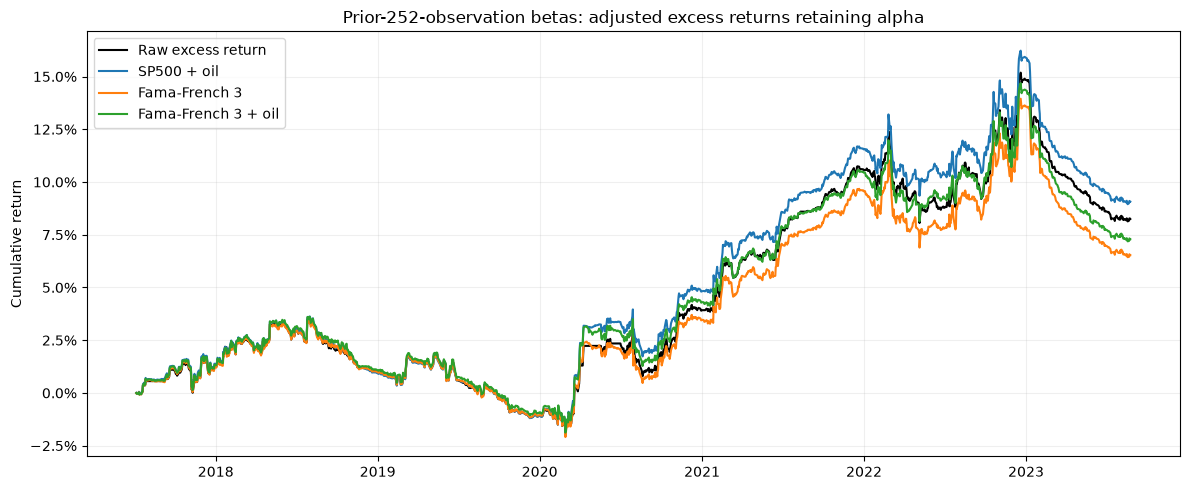

In [7]:
rolling_paths = {}
for name, cols in MODELS.items():
    X = sm.add_constant(sample[cols], has_constant='add').to_numpy()
    y = sample['Portfolio-RF'].to_numpy()
    rows = []
    for i in range(252, len(sample)):
        beta = np.linalg.lstsq(X[i-252:i], y[i-252:i], rcond=None)[0]
        adjusted = y[i] - X[i, 1:] @ beta[1:]
        rows.append((sample.index[i], adjusted, adjusted - beta[0], beta[0]))
    rolling_paths[name] = pd.DataFrame(rows, columns=['Date', 'Alpha retained', 'Forecast error', 'Prior daily alpha']).set_index('Date')
rolling_comparison = pd.DataFrame({name: {
    'Sessions': len(p), 'Adjusted mean annual': p['Alpha retained'].mean()*252,
    'Adjusted mean / vol (annual)': p['Alpha retained'].mean()/p['Alpha retained'].std(ddof=1)*np.sqrt(252),
    'Forecast error mean annual': p['Forecast error'].mean()*252,
} for name, p in rolling_paths.items()}).T
display(rolling_comparison)
fig, ax = plt.subplots(figsize=(12, 5))
rolling_dates = next(iter(rolling_paths.values())).index
ax.plot(rolling_dates, (1 + sample.loc[rolling_dates, 'Portfolio-RF']).cumprod()-1, label='Raw excess return', color='black')
for name, path in rolling_paths.items():
    assert path['Alpha retained'].gt(-1).all()
    ax.plot(path.index, (1+path['Alpha retained']).cumprod()-1, label=name)
ax.set(title='Prior-252-observation betas: adjusted excess returns retaining alpha', ylabel='Cumulative return')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'rolling_adjusted_returns.png', dpi=150)
plt.show()


## Stock-level residualization

For every stock appearing in the saved selected-pair list, regress adjusted-close daily excess returns on each factor set. Stocks enter only where consecutive portfolio-calendar prices and all factors exist; missing stock prices are not filled. Each stock can have a different sample, which is reported.

These regressions span the research period wherever prices exist, including dates when a stock was not held. They describe the selected stocks, rather than portfolio-weighted P&L. Full-sample residuals and alpha-retaining series are exported. Their equal-weight average would **not** reproduce this strategy's changing pair allocations, short positions, and fixed share quantities. Stock p-values are exploratory and have no multiple-testing correction.

In [8]:
stock_metrics, stock_coefficients, stock_residuals = [], [], []
for ticker in tickers:
    bars = pd.read_csv(ROOT / 'data/historical' / f'{ticker}.csv', usecols=['Date', 'Adj Close'], parse_dates=['Date'])
    assert not bars.Date.duplicated().any(), ticker
    price = pd.to_numeric(bars.set_index('Date')['Adj Close'], errors='raise').sort_index()
    assert price.dropna().gt(0).all(), ticker
    stock_return = price.reindex(calendar).pct_change(fill_method=None).reindex(sample.index)
    joined = sample.join(stock_return.rename('Stock return')).dropna()
    if len(joined) <= 252:
        raise ValueError(f'Insufficient stock coverage for {ticker}: {len(joined)}')
    for name, cols in MODELS.items():
        y = joined['Stock return'] - joined.RF
        fit, table = fit_model(y, joined[cols])
        adjusted = y - joined[cols].mul(fit.params[cols], axis=1).sum(axis=1)
        np.testing.assert_allclose(adjusted, fit.params['const'] + fit.resid, atol=1e-12)
        assert abs(fit.resid.mean()) < 1e-12
        stock_metrics.append({'Stock': ticker, 'Model': name, 'Sessions': len(joined),
            'First date': joined.index.min(), 'Last date': joined.index.max(),
            'Missing common dates': len(sample)-len(joined), 'R squared': fit.rsquared,
            'Alpha annual (arithmetic)': fit.params['const']*252, 'Alpha HAC p-value': fit.pvalues['const']})
        stock_coefficients.append(table.rename_axis('Term').reset_index().assign(Stock=ticker, Model=name))
        stock_residuals.append(pd.DataFrame({'Stock': ticker, 'Model': name,
            'Excess return': y, 'Alpha retained': adjusted, 'Strict residual': fit.resid}).rename_axis('Date').reset_index())
stock_summary = pd.DataFrame(stock_metrics)
display(stock_summary.groupby('Model').agg(Stocks=('Stock','size'), Median_R_squared=('R squared','median'),
    Median_annual_alpha=('Alpha annual (arithmetic)','median'), Minimum_sessions=('Sessions','min')))
display(stock_summary.loc[stock_summary.Model.eq('Fama-French 3 + oil')].sort_values('R squared', ascending=False).head(15))


,Stocks,Median_R_squared,Median_annual_alpha,Minimum_sessions
Model,,,,
Fama-French 3,99,0.457569,0.016816,1753
Fama-French 3 + oil,99,0.476758,0.017789,1753
SP500 + oil,99,0.383102,0.021756,1753


,Stock,Model,Sessions,First date,Last date,Missing common dates,R squared,Alpha annual (arithmetic),Alpha HAC p-value
134,JPM,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.768475,0.060513,0.253126
35,BAC,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.767010,0.033990,0.595550
224,RF,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.759963,0.082693,0.208821
20,AMP,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.759733,0.094347,0.177607
44,C,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.759720,-0.075343,0.231132
107,FITB,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.751050,0.010971,0.878916
206,PNC,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.749577,0.005973,0.919709
50,CFG,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.741871,0.020321,0.773586
143,L,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.730828,-0.021671,0.666436
137,KEY,Fama-French 3 + oil,1753,2016-07-01,2023-08-24,0,0.724572,-0.009019,0.908174


## Findings and saved results

Use the alpha confidence interval to assess whether the remaining mean is distinguishable from zero under this regression specification. A low $R^2$ means factors explain little day-to-day variation; it does not by itself establish alpha. Oil covers one commodity exposure, and FF3 does not cover momentum, profitability, investment, liquidity, or all nonlinear/time-varying exposures. HAC estimates help with dependence but do not fix strategy-selection bias or omitted variables.

In [9]:
for name, fit in fits.items():
    lo, hi = fit.conf_int().loc['const'] * 252
    assessment = 'excludes zero' if lo > 0 or hi < 0 else 'includes zero'
    display(Markdown(f"**{name}:** annual arithmetic alpha **{fit.params['const']*252:.2%}**, "
        f"95% HAC interval **[{lo:.2%}, {hi:.2%}]** ({assessment}); "
        f"p = **{fit.pvalues['const']:.4f}**, R² = **{fit.rsquared:.2%}**."))
display(Markdown('Strict full-sample residual means are zero by construction. '
    'Any remaining alpha is conditional on the chosen factors and this selected historical sample, '
    'rather than proof of new tradable information. Compare the prior-window adjusted paths before drawing conclusions.'))
comparison.to_csv(OUT / 'portfolio_model_comparison.csv')
pd.concat(coefficients, names=['Model', 'Term']).to_csv(OUT / 'portfolio_coefficients.csv')
pd.DataFrame(hac_sensitivity).to_csv(OUT / 'hac_sensitivity.csv', index=False)
proxy_coefficients.to_csv(OUT / 'dgs3mo_proxy_coefficients.csv')
sample.to_csv(OUT / 'aligned_regression_data.csv')
coverage.to_csv(OUT / 'factor_coverage.csv')
rolling_comparison.to_csv(OUT / 'rolling_model_comparison.csv')
for name, path in rolling_paths.items():
    path.to_csv(OUT / (name.replace(' ', '_') + '_rolling_daily.csv'))
stock_summary.to_csv(OUT / 'stock_model_summary.csv', index=False)
pd.concat(stock_coefficients, ignore_index=True).to_csv(OUT / 'stock_coefficients.csv', index=False)
pd.concat(stock_residuals, ignore_index=True).to_csv(OUT / 'stock_residual_returns.csv.gz', index=False, compression='gzip')
(OUT / 'analysis_manifest.json').write_text(json.dumps({
    'source_run': run.name, 'source_folder': folder.name, 'parameters': params,
    'saved_sharpe': float(winner['Sharpe Ratio']), 'sources': sources,
    'portfolio_sha256': hashlib.sha256((folder / 'portfolio_daily.csv').read_bytes()).hexdigest(),
    'models': MODELS, 'risk_free': 'French daily RF, with lagged DGS3MO sensitivity',
    'common_sessions': len(sample), 'omitted_sessions': len(omitted),
    'hac_lags': HAC_LAGS, 'rolling_prior_observations': 252,
    'annualization': '252 sessions; arithmetic alpha',
    'limitations': 'Selected research sample; zero costs; retrospective factors; stock diagnostics are not strategy P&L'
}, indent=2))
print(f'Saved plots, coefficients, daily residuals, coverage, and manifest to {OUT.relative_to(ROOT)}')


**SP500 + oil:** annual arithmetic alpha **1.08%**, 95% HAC interval **[-0.84%, 2.99%]** (includes zero); p = **0.2703**, R² = **0.28%**.

**Fama-French 3:** annual arithmetic alpha **1.04%**, 95% HAC interval **[-0.89%, 2.97%]** (includes zero); p = **0.2913**, R² = **0.27%**.

**Fama-French 3 + oil:** annual arithmetic alpha **1.08%**, 95% HAC interval **[-0.85%, 3.00%]** (includes zero); p = **0.2729**, R² = **0.59%**.

Strict full-sample residual means are zero by construction. Any remaining alpha is conditional on the chosen factors and this selected historical sample, rather than proof of new tradable information. Compare the prior-window adjusted paths before drawing conclusions.

Saved plots, coefficients, daily residuals, coverage, and manifest to outputs/factor_residual_analysis_zero_cost/cb64c19613e1e11beb71/formation_months_18_trading_months_6_correlation_threshold_0.8_eg_significance_0.01_entry_z_1.5_exit_z_0.5_stop_z_4
